# Group 3 Blink Detection - Computer Vision Project

## Cloning YOLO

### Connect Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Importing** required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import glob
import json
import os
import shutil
import zipfile

from PIL import Image
from collections import Counter, defaultdict

In [ ]:
!pip uninstall torch torchvision torchaudio -y

In [ ]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

Looking in indexes: https://download.pytorch.org/whl/cu118
  Using cached torch-2.7.1%2Bcu118-cp313-cp313-win_amd64.whl.metadata (27 kB)
  Using cached torchvision-0.22.1%2Bcu118-cp313-cp313-win_amd64.whl.metadata (6.3 kB)
  Using cached torchaudio-2.7.1%2Bcu118-cp313-cp313-win_amd64.whl.metadata (6.8 kB)
Using cached torch-2.7.1%2Bcu118-cp313-cp313-win_amd64.whl (2817.2 MB)
Using cached torchvision-0.22.1%2Bcu118-cp313-cp313-win_amd64.whl (5.5 MB)
Using cached torchaudio-2.7.1%2Bcu118-cp313-cp313-win_amd64.whl (4.1 MB)

   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ----------------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch

print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
  print("GPU Device Name:", torch.cuda.get_device_name(0))

GPU Available: True
GPU Device Name: NVIDIA GeForce RTX 2060 SUPER


In [ ]:
%cd "/content/drive/MyDrive/Colab Notebooks"
!ls

/content/drive/MyDrive/Colab Notebooks
blink_detector_training.ipynb  ultralytics	Untitled1.ipynb  yolov8s.pt
runs			       Untitled0.ipynb	yolov8n.pt	 zidane.jpg


### Install YOLOv8

In [ ]:
!pip install ultralytics

import ultralytics
ultralytics.checks()

from ultralytics import YOLO

Ultralytics 8.4.202  Python-3.13.5 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 2060 SUPER, 8192MiB)
Setup complete  (12 CPUs, 31.9 GB RAM, 508.4/931.5 GB disk)


In [3]:
!git clone https://github.com/ultralytics/ultralytics.git

Cloning into 'ultralytics'...


## Data Preprocessing

*Defining* paths to train and test folders.

In [4]:
# Main project directory
project_dir = "blink-detector"

# Original Roboflow dataset
zip_path = os.path.join(project_dir, "dataset.zip")
source_dir = os.path.join(project_dir, "coco_source")

# Our collected images
our_images_dir = os.path.join(project_dir, "our_images")
our_image_dir = os.path.join(our_images_dir, "images")
our_label_dir = os.path.join(our_images_dir, "labels")

# Final YOLO dataset
output_dir = os.path.join(project_dir, "dataset")

# Image and label directories
image_dir = os.path.join(output_dir, "images")
label_dir = os.path.join(output_dir, "labels")

print("Project directory:", project_dir)
print("Roboflow ZIP exists:", os.path.exists(zip_path))
print("Collected images folder exists:", os.path.exists(our_image_dir))

Project directory: blink-detector
Roboflow ZIP exists: True
Collected images folder exists: True


### Extracting the Roboflow dataset

In [5]:
# Extract Roboflow dataset

os.makedirs(source_dir, exist_ok=True)
required_splits = ["train", "valid", "test"]
if not all(os.path.isdir(os.path.join(source_dir, split))
           for split in required_splits):

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(source_dir)
    print("Extraction complete")
else:
    print("Roboflow dataset already extracted.")

Extraction complete


### Defining train and validation directories

In [6]:
# Roboflow training and validation directories

train_dir = os.path.join(source_dir, "train")
valid_dir = os.path.join(source_dir, "valid")

print("Training directory exists:", os.path.exists(train_dir))
print("Validation directory exists:", os.path.exists(valid_dir))

Training directory exists: True
Validation directory exists: True


### Fixing directories for YOLO structure

In [7]:
# Create YOLO dataset directories
folders = [
    os.path.join(image_dir, "train"),
    os.path.join(image_dir, "val"),
    os.path.join(label_dir, "train"),
    os.path.join(label_dir, "val")
]

# Clear previously generated folders
for folder in folders:

    if os.path.exists(folder):
        shutil.rmtree(folder)

    os.makedirs(folder, exist_ok=True)

print("YOLO directories created.")

YOLO directories created.


### Convert COCO to YOLO format

In [30]:
category_mapping = {
    "awake": 0,
    "sleeping": 1
}

class_names = {
    0: "Awake",
    1: "Sleeping"
}

### Convert annotations and copy images

In [31]:
def convert_dataset(split_dir, split_name):

    # Load COCO annotations
    annotation_path = os.path.join(
        split_dir, "_annotations.coco.json"
    )

    with open(annotation_path, "r") as f:
        coco_data = json.load(f)

    # Map COCO category IDs to YOLO class IDs
    category_ids = {}

    for category in coco_data["categories"]:
        category_name = category["name"].lower()
        if category_name in category_mapping:
            category_ids[category["id"]] = category_mapping[category_name]

    # Group annotations by image ID
    annotations_by_image = defaultdict(list)

    for annotation in coco_data["annotations"]:
        annotations_by_image[annotation["image_id"]].append(annotation)

    converted_count = Counter()
    image_count = 0
    missing_images = []

    for image in coco_data["images"]:

        image_id = image["id"]
        filename = image["file_name"]
        image_path = os.path.join(split_dir, filename)

        # Check if image exists
        if not os.path.exists(image_path):
            missing_images.append(filename)
            continue

        # Copy image into YOLO directory
        image_name = os.path.splitext(os.path.basename(filename))[0] + ".jpg"

        destination_image = os.path.join(
            image_dir, split_name, image_name
        )

        # Convert image to RGB and save as JPEG
        img = Image.open(image_path).convert("RGB")
        img.save(destination_image, "JPEG")

        # Create corresponding TXT label file
        label_filename = os.path.splitext(image_name)[0] + ".txt"

        label_path = os.path.join(
            label_dir, split_name, label_filename
        )

        labels = []

        for annotation in annotations_by_image.get(image_id, []):
            category_id = annotation["category_id"]

            # Ignore categories outside Open and Closed
            if category_id not in category_ids:
                continue
            x, y, width, height = annotation["bbox"]
            image_width = image["width"]
            image_height = image["height"]

            # Convert COCO coordinates to YOLO coordinates
            x_center = (x + width / 2) / image_width
            y_center = (y + height / 2) / image_height
            normalized_width = width / image_width
            normalized_height = height / image_height
            class_id = category_ids[category_id]
            labels.append(
                f"{class_id} {x_center:.6f} {y_center:.6f} "
                f"{normalized_width:.6f} {normalized_height:.6f}"
            )

            converted_count[class_id] += 1

        # Save TXT annotation file
        with open(label_path, "w") as f:
            f.write("\n".join(labels))

        image_count += 1

    print(f"\n{split_name.upper()} conversion complete")
    print("Images copied:", image_count)
    print("Open annotations:", converted_count[0])
    print("Closed annotations:", converted_count[1])
    print("Missing images:", len(missing_images))

    if missing_images:
        print("Missing image files:", missing_images)

    return image_count

### Convert training and validation datasets

In [32]:
# Convert Roboflow training dataset
train_count = convert_dataset(train_dir, "train")

# Convert Roboflow validation dataset
val_count = convert_dataset(valid_dir, "val")


TRAIN conversion complete
Images copied: 619
Open annotations: 280
Closed annotations: 345
Missing images: 0

VAL conversion complete
Images copied: 174
Open annotations: 79
Closed annotations: 96
Missing images: 0


### Check for missing images and labels

In [33]:
for split in ["train", "val"]:

    images = glob.glob(
        os.path.join(image_dir, split, "*.jpg")
    )

    labels = glob.glob(
        os.path.join(label_dir, split, "*.txt")
    )

    image_names = {
        os.path.splitext(os.path.basename(f))[0]
        for f in images
    }

    label_names = {
        os.path.splitext(os.path.basename(f))[0]
        for f in labels
    }

    missing_labels = image_names - label_names
    missing_images = label_names - image_names

    print(f"\n{split.upper()} DATASET")
    print("Total images:", len(images))
    print("Total labels:", len(labels))
    print("Images without labels:", len(missing_labels))
    print("Labels without images:", len(missing_images))


TRAIN DATASET
Total images: 619
Total labels: 619
Images without labels: 0
Labels without images: 0

VAL DATASET
Total images: 174
Total labels: 174
Images without labels: 0
Labels without images: 0


### YOLO config file

In [34]:
# Create data.yaml
yaml_content = f"""
path: {output_dir}
train: images/train
val: images/val

nc: 2
names:
  0: Awake
  1: Sleeping
"""

yaml_path = os.path.join(output_dir, "data.yaml")

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("YOLO configuration file created:", yaml_path)

YOLO configuration file created: blink-detector\dataset\data.yaml


Visualizing some pictures from the dataset

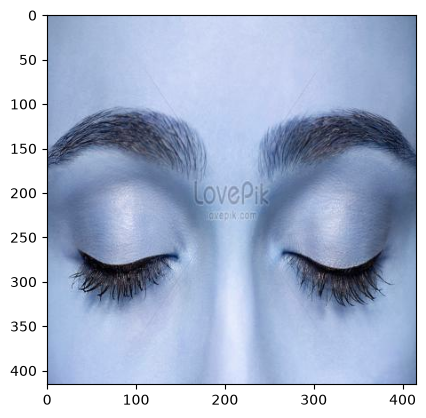

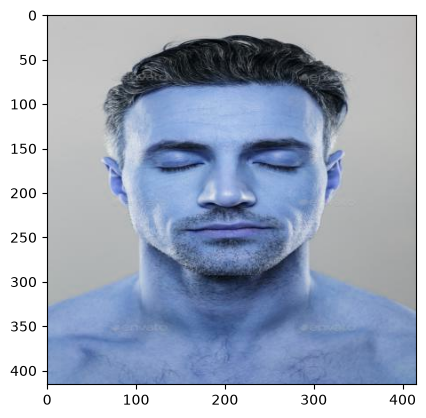

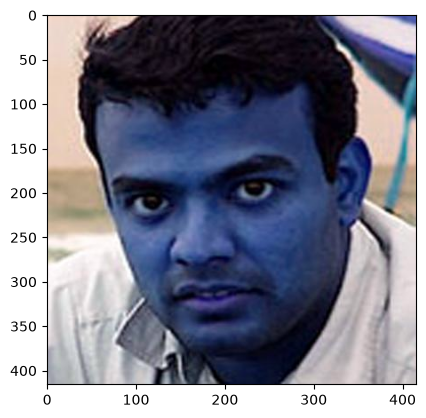

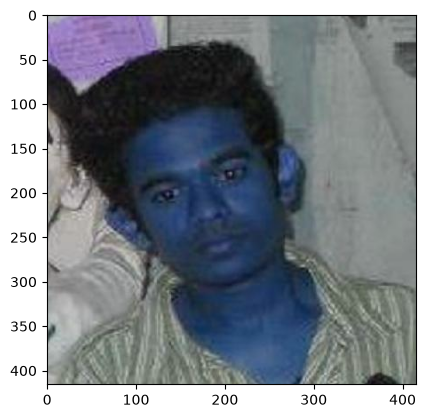

In [35]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir, "train"))):
    img = cv2.imread(os.path.join(image_dir,"train", image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

## Creating Text files for labels

Creating Dataframes from COCO annotations

In [37]:
# Creating a dataframe from COCO annotations

df = {
    'name': [],
    'label': [],
    'width': [],
    'height': [],
    'xmin': [],
    'ymin': [],
    'xmax': [],
    'ymax': []
}

# Load COCO annotation file
annotation_path = os.path.join(
    source_dir, "train", "_annotations.coco.json"
)

with open(annotation_path, "r") as f:
    coco_data = json.load(f)

# Create dictionary to match image IDs with filenames
image_dict = {
    image['id']: image
    for image in coco_data['images']
}

# Read annotations and extract image and bounding box information
for idx, anno in enumerate(coco_data['annotations']):

    image = image_dict[anno['image_id']]

    filename = os.path.splitext(image['file_name'])[0]

    width = image['width']
    height = image['height']

    # Get class label
    category_id = anno['category_id']

    category_name = next(
        category['name']
        for category in coco_data['categories']
        if category['id'] == category_id
    )

    # Keep only Open and Closed classes
    if category_name.lower() not in ['awake', 'sleeping']:
        continue

    label = category_name.capitalize()

    # COCO bounding box format: x, y, width, height
    x, y, box_width, box_height = anno['bbox']

    # Convert to xmin, ymin, xmax, ymax
    xmin = int(round(x))
    ymin = int(round(y))
    xmax = int(round(x + box_width))
    ymax = int(round(y + box_height))

    # Add information to dataframe dictionary
    df['name'].append(filename)
    df['label'].append(label)
    df['width'].append(width)
    df['height'].append(height)
    df['xmin'].append(xmin)
    df['ymin'].append(ymin)
    df['xmax'].append(xmax)
    df['ymax'].append(ymax)

# Convert dictionary into pandas dataframe
df = pd.DataFrame(df)

print("Dataframe created successfully")
print("Total annotations:", len(df))

df.head()

Dataframe created successfully
Total annotations: 625


,name,label,width,height,xmin,ymin,xmax,ymax
0,266_jpg.rf.002b3312311349ecf4881cc7f806dad2,Awake,416,416,89,147,346,221
1,istockphoto-1214296274-612x612_jpg.rf.008a7995...,Sleeping,416,416,162,55,227,110
2,augmented_image_309_jpg.rf.009456dfbab57e37ed9...,Awake,416,416,84,140,314,212
3,425_jpg.rf.00de00188e7901d1aeeb98d4a6e59973,Awake,416,416,101,139,328,226
4,istockphoto-1017325802-612x612_jpg.rf.01272022...,Sleeping,416,416,178,67,215,111


Do the same for validation data labels.

In [38]:
# Creating a dataframe from COCO validation annotations

df2 = {
    'name': [],
    'label': [],
    'width': [],
    'height': [],
    'xmin': [],
    'ymin': [],
    'xmax': [],
    'ymax': []
}

# Load COCO validation annotation file
val_annotation_path = os.path.join(
    source_dir, "valid", "_annotations.coco.json"
)

with open(val_annotation_path, "r") as f:
    val_coco_data = json.load(f)

# Create dictionary to match image IDs with filenames
val_image_dict = {
    image['id']: image
    for image in val_coco_data['images']
}

# Create dictionary to match category IDs with class names
val_category_dict = {
    category['id']: category['name']
    for category in val_coco_data['categories']
}

# Read annotations and extract image and bounding box information
for idx, anno in enumerate(val_coco_data['annotations']):

    image = val_image_dict[anno['image_id']]

    filename = os.path.splitext(image['file_name'])[0]

    width = image['width']
    height = image['height']

    # Get class label
    category_id = anno['category_id']
    category_name = val_category_dict[category_id]

    # Keep only Open and Closed classes
    if category_name.lower() not in ['awake', 'sleeping']:
        continue

    label = category_name.capitalize()

    # COCO bounding box format: x, y, width, height
    x, y, box_width, box_height = anno['bbox']

    # Convert to xmin, ymin, xmax, ymax
    xmin = int(round(x))
    ymin = int(round(y))
    xmax = int(round(x + box_width))
    ymax = int(round(y + box_height))

    # Add information to dataframe dictionary
    df2['name'].append(filename)
    df2['label'].append(label)
    df2['width'].append(width)
    df2['height'].append(height)
    df2['xmin'].append(xmin)
    df2['ymin'].append(ymin)
    df2['xmax'].append(xmax)
    df2['ymax'].append(ymax)

# Convert dictionaries into pandas dataframes
train_df = pd.DataFrame(df)
val_df = pd.DataFrame(df2)

print("Validation dataframe created successfully")
print("Total validation annotations:", len(val_df))

val_df.head()


Validation dataframe created successfully
Total validation annotations: 175


,name,label,width,height,xmin,ymin,xmax,ymax
0,istockphoto-501233182-612x612_jpg.rf.406a12e2a...,Sleeping,416,416,119,273,294,356
1,brock-wegner-Jv43LlmvTfs-unsplash_jpg.rf.393d4...,Sleeping,416,416,169,137,251,162
2,398_jpg.rf.3cff723a61e3926d32412528c63d4f76,Awake,416,416,98,136,352,220
3,short-hairstyles-for-indian-faces-406016-india...,Awake,416,416,71,139,261,218
4,augmented_image_51_jpg.rf.448e80390abf3d0304a9...,Awake,416,416,94,153,326,206


In [39]:
# Creating YOLO text files for each validation image

# Create directory to store validation text labels
val_txt_dir = os.path.join(source_dir, "valid", "labels")
os.makedirs(val_txt_dir, exist_ok=True)

# Map class names to YOLO class IDs
class_map = {
    'Awake': 0,
    'Sleeping': 1
}

# Convert bounding boxes and create individual text files
for filename in val_df['name'].unique():

    image_df = val_df[val_df['name'] == filename]

    txt_path = os.path.join(val_txt_dir, filename + ".txt")

    with open(txt_path, "w") as f:

        for _, row in image_df.iterrows():

            # Get class ID
            class_id = class_map[row['label']]

            # Normalize bounding box coordinates
            x_center = ((row['xmin'] + row['xmax']) / 2) / row['width']
            y_center = ((row['ymin'] + row['ymax']) / 2) / row['height']

            box_width = (row['xmax'] - row['xmin']) / row['width']
            box_height = (row['ymax'] - row['ymin']) / row['height']

            # Write YOLO format annotation
            f.write(
                f"{class_id} {x_center} {y_center} "
                f"{box_width} {box_height}\n"
            )

print("Validation YOLO text files created successfully")
print("Total validation text files:", len(os.listdir(val_txt_dir)))


Validation YOLO text files created successfully
Total validation text files: 174


### Visualize with bounding box

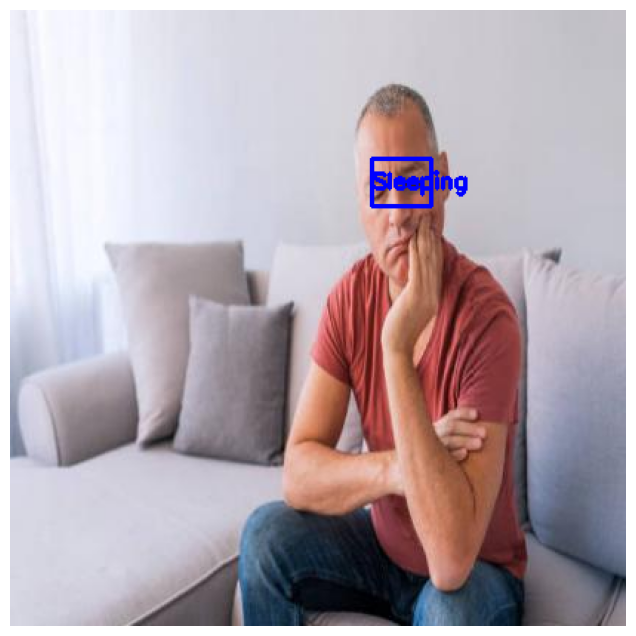

In [40]:

# Visualizing an image from the training dataset with bounding boxes

import cv2
import matplotlib.pyplot as plt
import glob

# Select an image to visualize
index = 10

# Get image filename from training dataframe
filename = train_df.iloc[index]['name']

# Find the image file
image_paths = (
    glob.glob(os.path.join(source_dir, "train", filename + ".*")) +
    glob.glob(os.path.join(source_dir, "train", "images", filename + ".*"))
)

if not image_paths:
    raise FileNotFoundError(f"Could not find image: {filename}")

image_path = image_paths[0]

# Load image
image = cv2.imread(image_path)

# Get all annotations belonging to this image
image_annotations = train_df[train_df['name'] == filename]

# Draw bounding boxes and labels
for _, row in image_annotations.iterrows():

    cv2.rectangle(
        image,
        (int(row['xmin']), int(row['ymin'])),
        (int(row['xmax']), int(row['ymax'])),
        (255, 0, 0),
        2
    )

    label = row['label']

    cv2.putText(
        image,
        label,
        (int(row['xmin']), int(row['ymin']) + 20),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        2
    )

# Convert BGR to RGB for Matplotlib
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display image
plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis('off')
plt.show()


Check for other bounding boxes

In [41]:
print("Selected image:", train_df["name"].iloc[index])
filtered_df = train_df[
    train_df['name'] == train_df["name"].iloc[index]
]

print(filtered_df)

Selected image: istockphoto-1055485374-612x612_jpg.rf.03cbe9e87baed5ebe09097dc2a86d117
                                                 name     label  width  \
10  istockphoto-1055485374-612x612_jpg.rf.03cbe9e8...  Sleeping    416   

    height  xmin  ymin  xmax  ymax  
10     416   244   100   284   132  


Check DataFrame data types and missing values

In [42]:
print("TRAINING DATAFRAME")
train_df.info()

print("\nVALIDATION DATAFRAME")
val_df.info()

TRAINING DATAFRAME
<class 'pandas.DataFrame'>
RangeIndex: 625 entries, 0 to 624
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   name    625 non-null    str  
 1   label   625 non-null    str  
 2   width   625 non-null    int64
 3   height  625 non-null    int64
 4   xmin    625 non-null    int64
 5   ymin    625 non-null    int64
 6   xmax    625 non-null    int64
 7   ymax    625 non-null    int64
dtypes: int64(6), str(2)
memory usage: 82.0 KB

VALIDATION DATAFRAME
<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   name    175 non-null    str  
 1   label   175 non-null    str  
 2   width   175 non-null    int64
 3   height  175 non-null    int64
 4   xmin    175 non-null    int64
 5   ymin    175 non-null    int64
 6   xmax    175 non-null    int64
 7   ymax    175 non-null    int64
dtypes: int64(6), str(2)
m

In [43]:
print("Training missing values:")
print(train_df.isnull().sum())

print("\nValidation missing values:")
print(val_df.isnull().sum())

Training missing values:
name      0
label     0
width     0
height    0
xmin      0
ymin      0
xmax      0
ymax      0
dtype: int64

Validation missing values:
name      0
label     0
width     0
height    0
xmin      0
ymin      0
xmax      0
ymax      0
dtype: int64


Check unique class labels

In [44]:
print("Training labels:", train_df['label'].unique())
print("Validation labels:", val_df['label'].unique())

Training labels: <ArrowStringArray>
['Awake', 'Sleeping']
Length: 2, dtype: str
Validation labels: <ArrowStringArray>
['Sleeping', 'Awake']
Length: 2, dtype: str


Map labels to YOLO class IDs

In [45]:
label_map = {
    'Awake': 0,
    'Sleeping': 1
}

train_df['class'] = train_df['label'].map(label_map)
val_df['class'] = val_df['label'].map(label_map)

train_df.head()


,name,label,width,height,xmin,ymin,xmax,ymax,class
0,266_jpg.rf.002b3312311349ecf4881cc7f806dad2,Awake,416,416,89,147,346,221,0
1,istockphoto-1214296274-612x612_jpg.rf.008a7995...,Sleeping,416,416,162,55,227,110,1
2,augmented_image_309_jpg.rf.009456dfbab57e37ed9...,Awake,416,416,84,140,314,212,0
3,425_jpg.rf.00de00188e7901d1aeeb98d4a6e59973,Awake,416,416,101,139,328,226,0
4,istockphoto-1017325802-612x612_jpg.rf.01272022...,Sleeping,416,416,178,67,215,111,1


### Convert bounding boxes to YOLO format

In [46]:
# Training data
train_df['x_center'] = (
    train_df['xmin'] + train_df['xmax']
) / (2 * train_df['width'])

train_df['y_center'] = (
    train_df['ymin'] + train_df['ymax']
) / (2 * train_df['height'])

train_df['box_width'] = (
    train_df['xmax'] - train_df['xmin']
) / train_df['width']

train_df['box_height'] = (
    train_df['ymax'] - train_df['ymin']
) / train_df['height']

# Validation data
val_df['x_center'] = (
    val_df['xmin'] + val_df['xmax']
) / (2 * val_df['width'])

val_df['y_center'] = (
    val_df['ymin'] + val_df['ymax']
) / (2 * val_df['height'])

val_df['box_width'] = (
    val_df['xmax'] - val_df['xmin']
) / val_df['width']

val_df['box_height'] = (
    val_df['ymax'] - val_df['ymin']
) / val_df['height']


train_df.head()

,name,label,width,height,xmin,ymin,xmax,ymax,class,x_center,y_center,box_width,box_height
0,266_jpg.rf.002b3312311349ecf4881cc7f806dad2,Awake,416,416,89,147,346,221,0,0.522837,0.442308,0.617788,0.177885
1,istockphoto-1214296274-612x612_jpg.rf.008a7995...,Sleeping,416,416,162,55,227,110,1,0.467548,0.198317,0.156250,0.132212
2,augmented_image_309_jpg.rf.009456dfbab57e37ed9...,Awake,416,416,84,140,314,212,0,0.478365,0.423077,0.552885,0.173077
3,425_jpg.rf.00de00188e7901d1aeeb98d4a6e59973,Awake,416,416,101,139,328,226,0,0.515625,0.438702,0.545673,0.209135
4,istockphoto-1017325802-612x612_jpg.rf.01272022...,Sleeping,416,416,178,67,215,111,1,0.472356,0.213942,0.088942,0.105769


Check for invalid and missing values.

In [47]:
import numpy as np

# Training data
print("Before cleaning (training):", train_df.shape)

train_df.replace([np.inf, -np.inf], np.nan, inplace=True)
train_df.dropna(inplace=True)

print("After cleaning (training):", train_df.shape)


# Validation data
print("\nBefore cleaning (validation):", val_df.shape)

val_df.replace([np.inf, -np.inf], np.nan, inplace=True)
val_df.dropna(inplace=True)

print("After cleaning (validation):", val_df.shape)

Before cleaning (training): (625, 13)
After cleaning (training): (625, 13)

Before cleaning (validation): (175, 13)
After cleaning (validation): (175, 13)


Check the cleaned DataFrames

In [48]:
print("Training DataFrame:")
print(train_df.info())

print("\nValidation DataFrame:")
print(val_df.info())

Training DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 625 entries, 0 to 624
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   name        625 non-null    str    
 1   label       625 non-null    str    
 2   width       625 non-null    int64  
 3   height      625 non-null    int64  
 4   xmin        625 non-null    int64  
 5   ymin        625 non-null    int64  
 6   xmax        625 non-null    int64  
 7   ymax        625 non-null    int64  
 8   class       625 non-null    int64  
 9   x_center    625 non-null    float64
 10  y_center    625 non-null    float64
 11  box_width   625 non-null    float64
 12  box_height  625 non-null    float64
dtypes: float64(4), int64(7), str(2)
memory usage: 106.4 KB
None

Validation DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   na

In [49]:
# Check multiple bounding boxes for one image

filename = train_df['name'].iloc[3]
filtered_df = train_df[train_df['name'] == filename]
print(filtered_df)

                                          name  label  width  height  xmin  \
3  425_jpg.rf.00de00188e7901d1aeeb98d4a6e59973  Awake    416     416   101   

   ymin  xmax  ymax  class  x_center  y_center  box_width  box_height  
3   139   328   226      0  0.515625  0.438702   0.545673    0.209135  


Normalize into individual txt files.

In [50]:
# TRAINING DATA
train_label_dir = os.path.join(source_dir, "train", "labels")
os.makedirs(train_label_dir, exist_ok=True)

unique_names = train_df['name'].unique()
for name in unique_names:
    data = train_df[train_df['name'] == name]
    box_list = []

    for _, row in data.iterrows():

        box_list.append(
            f"{int(row['class'])} "
            f"{row['x_center']:.6f} "
            f"{row['y_center']:.6f} "
            f"{row['box_width']:.6f} "
            f"{row['box_height']:.6f}"
        )

    text = "\n".join(box_list)
    with open(os.path.join(train_label_dir, f"{name}.txt"), "w") as file:
        file.write(text)


# VALIDATION DATA
val_label_dir = os.path.join(source_dir, "valid", "labels")
os.makedirs(val_label_dir, exist_ok=True)
unique_names = val_df['name'].unique()

for name in unique_names:
    data = val_df[val_df['name'] == name]
    box_list = []

    for _, row in data.iterrows():

        box_list.append(
            f"{int(row['class'])} "
            f"{row['x_center']:.6f} "
            f"{row['y_center']:.6f} "
            f"{row['box_width']:.6f} "
            f"{row['box_height']:.6f}"
        )

    text = "\n".join(box_list)
    with open(os.path.join(val_label_dir, f"{name}.txt"), "w") as file:
        file.write(text)


print("Training text files:", len(os.listdir(train_label_dir)))
print("Validation text files:", len(os.listdir(val_label_dir)))
print("YOLO labels regenerated")

Training text files: 619
Validation text files: 174
YOLO labels regenerated


In [51]:
import os

train_label_dir = os.path.join(source_dir, "train", "labels")
val_label_dir = os.path.join(source_dir, "valid", "labels")

# Display one training label file
train_files = os.listdir(train_label_dir)
print("Example training label file:")
with open(os.path.join(train_label_dir, train_files[0]), "r") as f:
    print(f.read())

# Display one validation label file
val_files = os.listdir(val_label_dir)
print("\nExample validation label file:")
with open(os.path.join(val_label_dir, val_files[0]), "r") as f:
    print(f.read())

Example training label file:
1 0.501202 0.533654 0.939904 0.682692

Example validation label file:
0 0.532452 0.423077 0.685096 0.221154


## Checking Missing Files

In [52]:
import glob
import os

# Get all training and validation images
train_images = []
val_images = []
for ext in ["*.jpg", "*.jpeg", "*.png"]:
    train_images += glob.glob(os.path.join(source_dir, "train", "**", ext), recursive=True)
    val_images += glob.glob(os.path.join(source_dir, "valid", "**", ext), recursive=True)

# Get all training and validation labels
train_labels = glob.glob(os.path.join(source_dir, "train", "labels", "*.txt"))
val_labels = glob.glob(os.path.join(source_dir, "valid", "labels", "*.txt"))

# Get filenames without extensions
image_files_train = {os.path.splitext(os.path.basename(file))[0] for file in train_images}
label_files_train = {os.path.splitext(os.path.basename(file))[0] for file in train_labels}

image_files_val = {os.path.splitext(os.path.basename(file))[0] for file in val_images}
label_files_val = {os.path.splitext(os.path.basename(file))[0] for file in val_labels}

# Compare image and label counts
print(len(image_files_train), " = ", len(label_files_train))
print(len(image_files_val), " = ", len(label_files_val))

619  =  619
174  =  174


In [53]:
# TRAINING DATA
extra_images_train = image_files_train - label_files_train
extra_labels_train = label_files_train - image_files_train

print("Training Extra images:", extra_images_train)
print("Training Extra labels:", extra_labels_train)

# VALIDATION DATA
extra_images_val = image_files_val - label_files_val
extra_labels_val = label_files_val - image_files_val

print("Validation Extra images:", extra_images_val)
print("Validation Extra labels:", extra_labels_val)

Training Extra images: set()
Training Extra labels: set()
Validation Extra images: set()
Validation Extra labels: set()


## Custom object detection using YOLO

Install and check Ultalytics

In [54]:
import ultralytics
ultralytics.checks()

Ultralytics 8.4.202  Python-3.13.5 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 2060 SUPER, 8192MiB)
Setup complete  (12 CPUs, 31.9 GB RAM, 823.9/931.5 GB disk)


Import YOLO

In [55]:
from ultralytics import YOLO

## Training YOLO

In [56]:
model = YOLO('yolov8s.pt')  # pretrained model

In [57]:
model

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_s

In [58]:
print("Source directory:", source_dir)

print("\nTraining folder:")
print(os.listdir(os.path.join(source_dir, "train"))[:10])

print("\nValidation folder:")
print(os.listdir(os.path.join(source_dir, "valid"))[:10])

Source directory: blink-detector\coco_source

Training folder:
['0059-jpg_wh860_jpg.rf.9ed21bcb1b111a6fa5451ec2079f0909.jpg', '0C7A1623_jpg.rf.e604745faea8cd13aeaaf2849ca2da55.jpg', '1947555_jpg.rf.65c38098f18062c975347f22a0fdc926.jpg', '220_jpg.rf.cee70c53646d8eab456e500ece283ea1.jpg', '221_jpg.rf.3fe4f47aa2d262f3ecfe49a29678feda.jpg', '222_jpg.rf.61010da1dc1754511b727ca937962a45.jpg', '223_jpg.rf.2e69f95df569c68a24547ab428c37c56.jpg', '224_jpg.rf.82ef393d6ff4aed549d3488be38642b9.jpg', '225_jpg.rf.51575850aa63a536f0932ee801dc264a.jpg', '226_jpg.rf.9fd1620985af919ea103fbb179a7d779.jpg']

Validation folder:
['11707_jpg.rf.d78b8351506a3352955af1a31bde194d.jpg', '11986963-A-woman-s-face-with-closed-eyes_jpg.rf.75ffc4e4d6c47b931443088bfd562c5e.jpg', '1_tMdKwT1Vw-0tuGxpPHGEHA_jpeg.rf.87fb70c4a4cf43699180851d45c4a092.jpg', '242_jpg.rf.b0683916ac21ac56f2bf718ff4294751.jpg', '244_jpg.rf.33b2c856448aa702041319fd3569020c.jpg', '263_jpg.rf.03b96e51e1cc62c7a5abe7460b6d7f91.jpg', '271_jpg.rf.76c576

In [59]:
import os
import glob
import shutil

yolo_dir = os.path.join(source_dir, "yolo_dataset")

# Create YOLO folder structure
for folder in ["images/train", "images/val", "labels/train", "labels/val"]:
    os.makedirs(os.path.join(yolo_dir, folder), exist_ok=True)

# Copy training images
for image in glob.glob(os.path.join(source_dir, "train", "*.jpg")):
    shutil.copy2(image, os.path.join(yolo_dir, "images", "train"))

# Copy validation images
for image in glob.glob(os.path.join(source_dir, "valid", "*.jpg")):
    shutil.copy2(image, os.path.join(yolo_dir, "images", "val"))

# Copy training labels
for label in glob.glob(os.path.join(source_dir, "train", "labels", "*.txt")):
    shutil.copy2(label, os.path.join(yolo_dir, "labels", "train"))

# Copy validation labels
for label in glob.glob(os.path.join(source_dir, "valid", "labels", "*.txt")):
    shutil.copy2(label, os.path.join(yolo_dir, "labels", "val"))

print("YOLO dataset folders created successfully")

YOLO dataset folders created successfully


In [60]:
config_path = os.path.join(yolo_dir, "config.yaml")

config_content = """
path: blink-detector/coco_source/yolo_dataset

train: images/train
val: images/val

nc: 2

names:
  0: Awake
  1: Sleeping
"""

with open(config_path, "w") as f:
    f.write(config_content)

print("Configuration file created:", config_path)

Configuration file created: blink-detector\coco_source\yolo_dataset\config.yaml


In [61]:
print(config_path)
print(os.path.exists(config_path))

blink-detector\coco_source\yolo_dataset\config.yaml
True


## Evaluation Metrics

In [109]:
model.train(
    data=config_path,
    epochs=50,
    patience=5,
    batch=10,
    lr0=0.005,
    optimizer='SGD',
    device=0,
    project="blink-detector",
)

New https://pypi.org/project/ultralytics/8.4.203 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.202  Python-3.13.5 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 2060 SUPER, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=10, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=blink-detector\coco_source\yolo_dataset\config.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0

KeyboardInterrupt: 

In [104]:
metrics = model.val(
    project="blink-detector"
)
metrics.box.map      # mAP50-95
metrics.box.map50    # mAP50
metrics.box.map75    # mAP75
metrics.box.maps     # mAP50-95 for each class
metrics.box.mp       # Precision
metrics.box.mr       # Recall

Ultralytics 8.4.202  Python-3.13.5 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 2060 SUPER, 8192MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 234.0±150.4 MB/s, size: 20.2 KB)
val: Scanning E:\IAT360 CV Project\blink-detector\coco_source\yolo_dataset\labels\val.cache... 174 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 174/174 81.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 1.9s/it 20.9s
                   all        174        175      0.863      0.886       0.91      0.437
                 Awake         79         79      0.917      0.977      0.991       0.53
              Sleeping         95         96      0.809      0.795      0.829      0.344
Speed: 1.1ms preprocess, 7.2ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to E:\IAT360 CV Project\runs\detect\blink-detector\val-3


np.float64(0.885923426516763)

In [ ]:
metrics.box.map      # mAP50-95
metrics.box.map50    # mAP50
metrics.box.map75    # mAP75
metrics.box.maps     # mAP50-95 for each class
metrics.box.mp       # Precision
metrics.box.mr       # Recall

np.float64(0.9449275362318841)

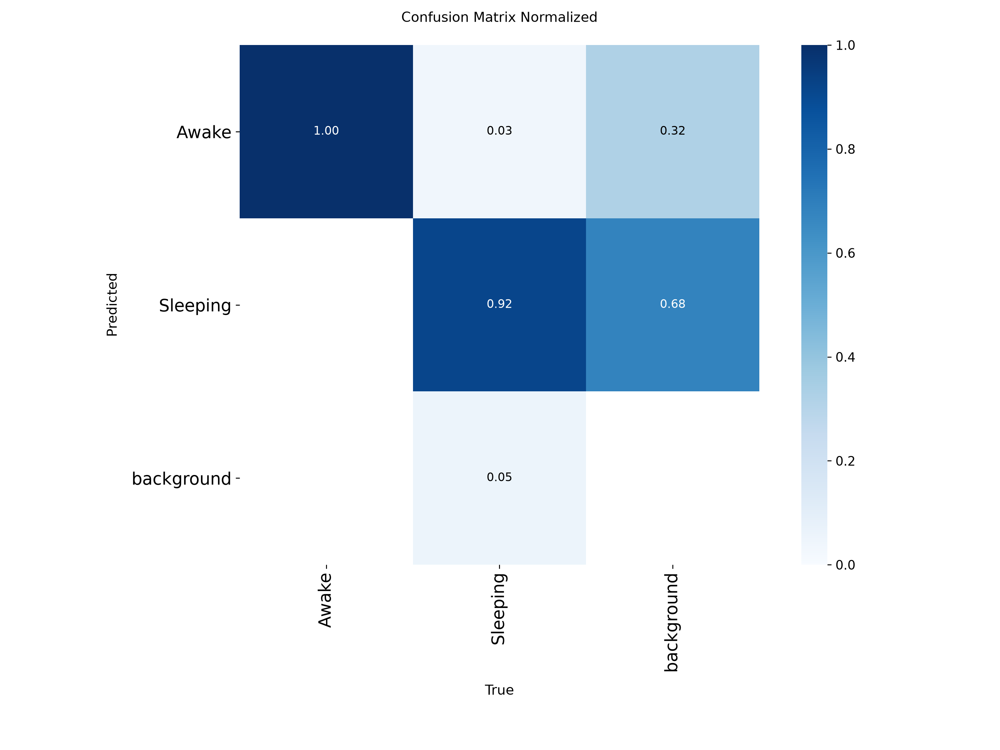

In [105]:
%matplotlib inline
from PIL import Image

Image.open('runs/detect/blink-detector/val-3/confusion_matrix_normalized.png')

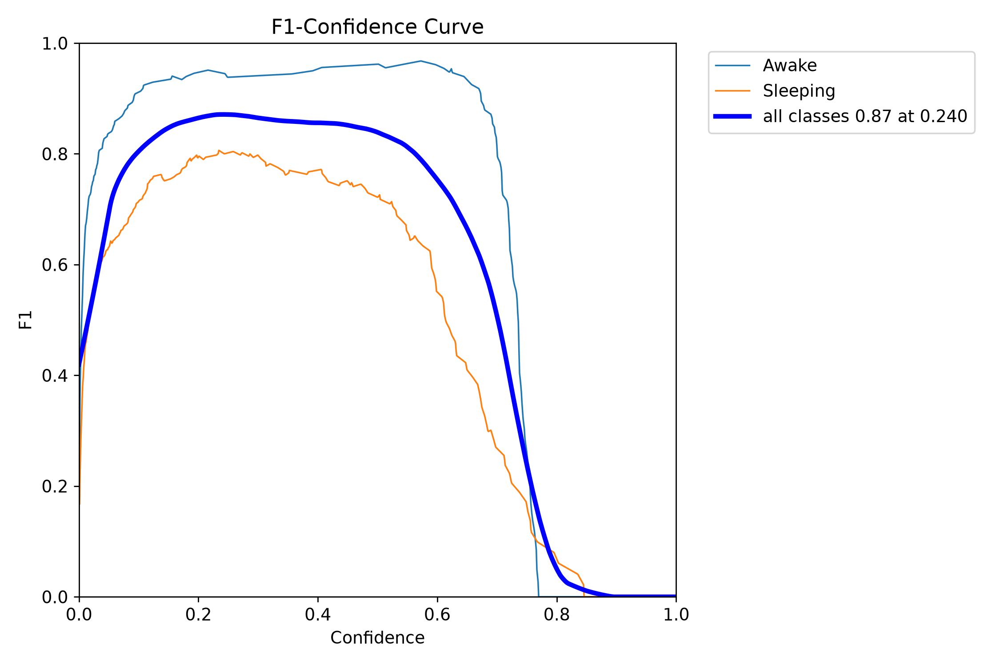

In [106]:
Image.open('runs/detect/blink-detector/val-3/BoxF1_curve.png')

## Prediction

Find the weight and best path

In [69]:
weights = glob.glob(
    "runs/detect/blink-detector/**/weights/best.pt",
    recursive=True
)

print(weights)

['runs/detect/blink-detector\\train\\weights\\best.pt']


In [70]:
model = YOLO("runs/detect/blink-detector/train/weights/best.pt")

Find an image

In [71]:
test_images_dir = os.path.join(our_images_dir, "images")
test_images = []

for ext in ["*.jpg", "*.jpeg", "*.png"]:
    test_images.extend(glob.glob(os.path.join(test_images_dir, ext)))

print("Number of collected images:", len(test_images))
print(test_images)

Number of collected images: 125
['blink-detector\\our_images\\images\\20190916_212413 1.jpg', 'blink-detector\\our_images\\images\\20250423_075706 1.jpg', 'blink-detector\\our_images\\images\\20250720_200347 1.jpg', 'blink-detector\\our_images\\images\\20250720_200428 1.jpg', 'blink-detector\\our_images\\images\\20250720_202229 1.jpg', 'blink-detector\\our_images\\images\\20250720_204834 1.jpg', 'blink-detector\\our_images\\images\\20250720_204901 1.jpg', 'blink-detector\\our_images\\images\\20250720_204902 1.jpg', 'blink-detector\\our_images\\images\\20250720_205035 1.jpg', 'blink-detector\\our_images\\images\\20250720_212828 1.jpg', 'blink-detector\\our_images\\images\\20250720_212831 1.jpg', 'blink-detector\\our_images\\images\\20250801_200829 1.jpg', 'blink-detector\\our_images\\images\\20251002_230529 1.jpg', 'blink-detector\\our_images\\images\\20260108_194237 1.jpg', 'blink-detector\\our_images\\images\\20260407_162542 1.jpg', 'blink-detector\\our_images\\images\\20260529_134721

In [96]:
results = model(
    test_images[40],
    save=True,
    show_labels=True,
    show_conf=True,
    conf=0.5,
    show_boxes=True,
    project="blink-detector",
    name="prediction",
    exist_ok=True
)


image 1/1 E:\IAT360 CV Project\blink-detector\our_images\images\20261027_130312 1.jpg: 288x640 1 Sleeping, 12.3ms
Speed: 1.7ms preprocess, 12.3ms inference, 1.6ms postprocess per image at shape (1, 3, 288, 640)
Results saved to E:\IAT360 CV Project\runs\detect\blink-detector\prediction


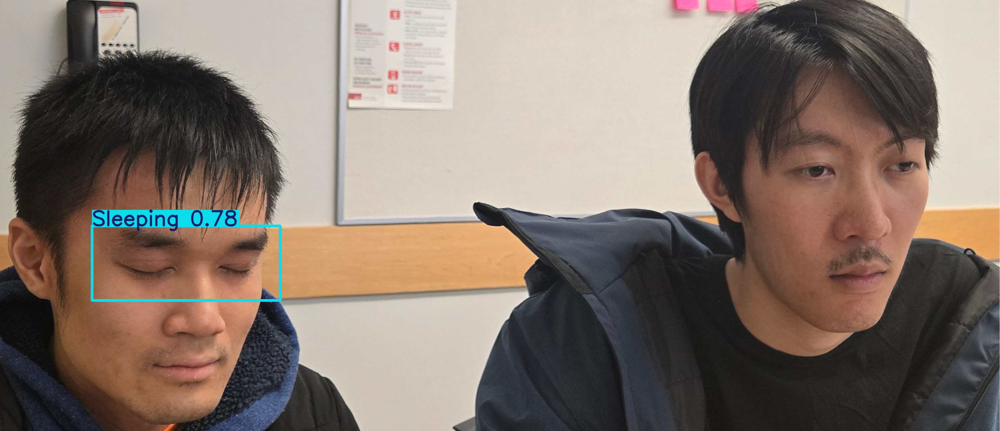

In [97]:
%matplotlib inline
from PIL import Image

Image.fromarray(results[0].plot()[:, :, ::-1])